# 02 · Data quality and exploratory analysis

Every section ends with a **Decision** that states what we do with the finding and why.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import config as C, load_data as L, results, plotting as P, organ as O, risk as R

P.setup()
pd.set_option("display.width", 160, "display.max_columns", 40)
rng = np.random.default_rng(C.RANDOM_SEED)
df = L.load_processed()
raw = L.load_raw_minimal()          # parsed only, -255 -> NaN, no other change
print(df.shape, df.index.min(), "->", df.index.max())

(48971, 71) 2024-01-19 14:00:00+01:00 -> 2025-11-29 17:20:00+01:00


## 1 · Missing data

### 1a · How much is missing, per sensor and over time?

,location,missing share (raw),missing share (clean)
AU,Outside,0.011,0.004
O1,Organ,0.001,0.001
AWn,North wall,0.834,0.834
AWs,South wall,0.464,0.461
AWo,East wall,0.505,0.503
K1,Art objects NW,0.378,0.373
K2,Art objects S,0.002,0.000
D1,Attic,0.030,0.031
Ke1,Basement,0.189,0.188


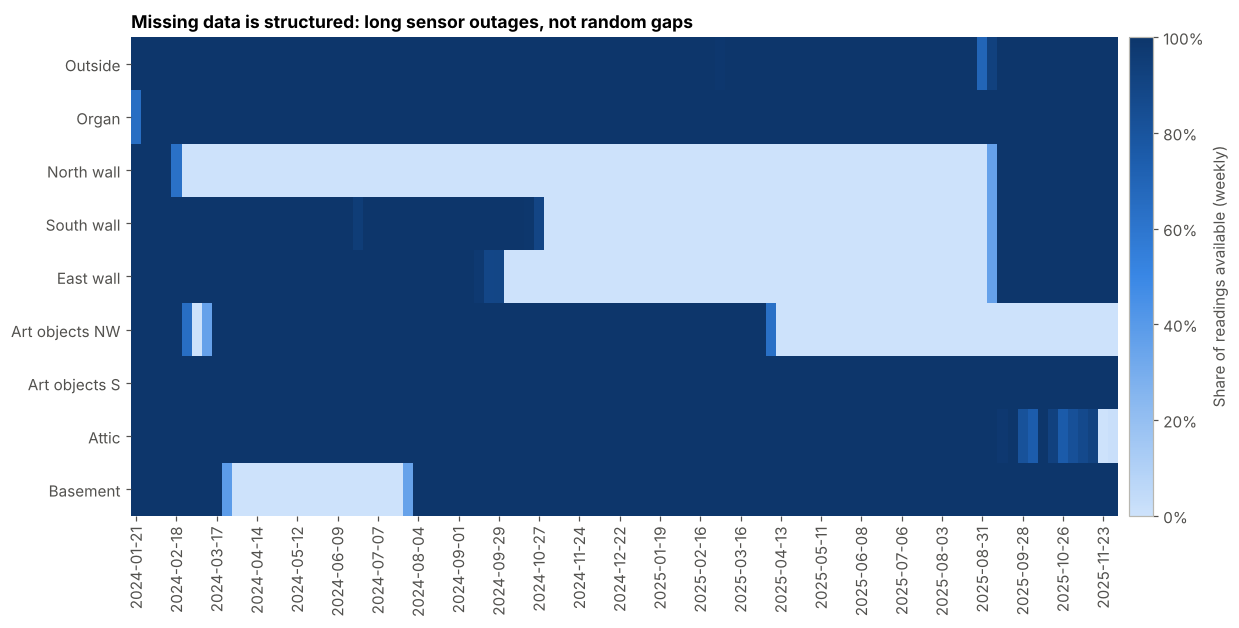

In [2]:
temp_cols = [f"temp_{s}" for s in C.SENSORS]
miss = pd.DataFrame({
    "location": [P.name(s) for s in C.SENSORS],
    "missing share (raw)": raw[temp_cols].isna().mean().values,
    "missing share (clean)": df[temp_cols].isna().mean().values,
}, index=list(C.SENSORS)).round(3)
display(miss)

daily_cov = df[temp_cols].notna().resample("W").mean()
daily_cov.index = daily_cov.index.strftime("%Y-%m-%d")
daily_cov.columns = list(C.SENSORS)
fig, ax = P.calendar_heatmap(daily_cov, "Missing data is structured: long sensor outages, not random gaps",
                             "Share of readings available (weekly)", cmap=P.SEQ_BLUE)
P.save(fig, "02_missing_heatmap.png"); plt.show()

### 1b · Length distribution of gaps

The length of the gaps decides whether interpolation is acceptable. We count every
interior gap in the *raw* temperature series of each sensor.

,Outside,Organ,North wall,South wall,East wall,Art objects NW,Art objects S,Attic,Basement
gap length (readings of 20 min),,,,,,,,,
1,275,41,28,118,89,250,69,44,49
2,15,4,0,4,3,15,5,2,1
3,3,1,1,4,1,2,0,0,0
4-6,1,0,0,1,0,0,0,2,1
7-18 (≤6 h),1,0,0,1,2,0,0,4,0
19-72 (≤1 d),0,0,0,0,2,0,0,12,0
73-504 (≤1 wk),1,0,0,0,0,0,0,1,0
> 1 week,0,0,1,1,1,1,0,1,1


gaps in total: 1059 | share of gaps <= 3 readings: 96.7% | but they hold only 1.09% of all missing readings


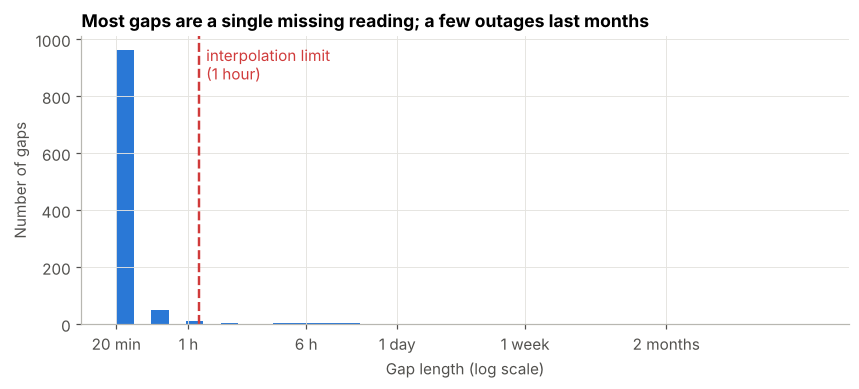

In [3]:
gl = {s: L.gap_lengths(raw[f"temp_{s}"]) for s in C.SENSORS}
bins = [0, 1, 2, 3, 6, 18, 72, 504, 10**6]
labels = ["1", "2", "3", "4-6", "7-18 (≤6 h)", "19-72 (≤1 d)", "73-504 (≤1 wk)", "> 1 week"]
gap_tab = pd.DataFrame({P.name(s): pd.cut(g, bins, labels=labels).value_counts().reindex(labels)
                        for s, g in gl.items()}).fillna(0).astype(int)
gap_tab.index.name = "gap length (readings of 20 min)"
display(gap_tab)
allg = pd.concat(gl.values())
share_le3 = (allg <= 3).mean()
missing_in_short = allg[allg <= 3].sum() / allg.sum()
print(f"gaps in total: {len(allg)} | share of gaps <= 3 readings: {share_le3:.1%} "
      f"| but they hold only {missing_in_short:.2%} of all missing readings")
results.save_table(gap_tab, "gap_lengths")
results.update(n_gaps=len(allg), share_gaps_le3=share_le3, missing_in_short_gaps=missing_in_short)

fig, ax = plt.subplots(figsize=(9, 3.4))
vals = np.sort(allg.values)
ax.hist(np.log10(vals), bins=40, color=P.SERIES[0])
ax.axvline(np.log10(3.5), color=P.STATUS["high"], ls="--")
ax.text(np.log10(3.5) + 0.05, ax.get_ylim()[1] * 0.85, "interpolation limit\n(1 hour)", color=P.STATUS["high"])
ticks = [1, 3, 18, 72, 504, 4320]
ax.set_xticks(np.log10(ticks), ["20 min", "1 h", "6 h", "1 day", "1 week", "2 months"])
ax.set_xlabel("Gap length (log scale)"); ax.set_ylabel("Number of gaps")
ax.set_title("Most gaps are a single missing reading; a few outages last months")
P.save(fig, "02_gap_lengths.png"); plt.show()

### 1c · Is 1 hour a good interpolation limit? Hold-out test

We take complete stretches of data, delete artificial gaps of known length, interpolate
them linearly and compare with the true values. If the error at 3 readings is still
small compared with the effects we analyse (≥ 1 °C organ events, LIM margins of several
% relative humidity), interpolation up to 1 h is harmless.

In [4]:
def holdout_error(s: pd.Series, length: int, n: int = 400) -> float:
    """Mean absolute error of linear interpolation over artificial gaps of ``length`` readings."""
    x = s.to_numpy()
    ok = np.where(pd.Series(x).rolling(length + 2).count().to_numpy() == length + 2)[0]  # fully valid windows
    starts = rng.choice(ok, size=min(n, len(ok)), replace=False) - length - 1
    errs = []
    for a in starts:
        left, right = x[a], x[a + length + 1]
        true = x[a + 1: a + length + 1]
        est = left + (right - left) * np.arange(1, length + 1) / (length + 1)
        errs.append(np.abs(est - true).mean())
    return float(np.mean(errs))

lengths = [1, 2, 3, 6, 9, 18]
targets = {"Organ air temp (°C)": raw["temp_O1"], "Organ humidity (%)": raw["rh_O1"],
           "Basement humidity (%)": raw["rh_Ke1"], "Outside temp (°C)": raw["temp_AU"],
           "Outside humidity (%)": raw["rh_AU"].clip(upper=100)}
hold = pd.DataFrame({k: [holdout_error(v, L_) for L_ in lengths] for k, v in targets.items()},
                    index=pd.Index(lengths, name="gap length (readings)")).round(3)
display(hold)
results.save_table(hold, "interp_holdout")
results.update(holdout_organ_temp_3=hold.loc[3, "Organ air temp (°C)"], holdout_organ_rh_3=hold.loc[3, "Organ humidity (%)"],
               holdout_out_temp_3=hold.loc[3, "Outside temp (°C)"], holdout_out_temp_18=hold.loc[18, "Outside temp (°C)"])

,Organ air temp (°C),Organ humidity (%),Basement humidity (%),Outside temp (°C),Outside humidity (%)
gap length (readings),,,,,
1,0.012,0.027,0.041,0.050,0.225
2,0.015,0.069,0.049,0.062,0.269
3,0.015,0.065,0.054,0.085,0.386
6,0.026,0.072,0.105,0.179,0.546
9,0.031,0.096,0.135,0.259,0.931
18,0.078,0.189,0.275,0.620,2.070


### 1d · Sensitivity of results to the interpolation limit (2, 3, 6 readings)

We rerun the complete pipeline with limits of 2, 3 and 6 readings and recompute the two
headline results: organ events and the mold-risk shares.

In [5]:
raw_file = L.read_raw()
sens = []
for lim in [0, 2, 3, 6]:
    d, clog_k, _ = L.clean(raw_file, interp_limit=lim)
    ev = O.detect_events(d["temp_O1"])
    summ = R.summarize(R.risk_table(d))
    sens.append(dict(limit=lim, filled=int(clog_k.query("step=='interpolate'").n_values.sum()),
                     organ_events=len(ev), organ_episodes=len(O.merge_episodes(ev)),
                     **{f"high share {s}": round(summ.loc[s, "share_high"], 4) for s in ["Ke1", "K1", "AWn", "O1"]},
                     ranking=" > ".join(summ.index)))
sens = pd.DataFrame(sens).set_index("limit")
display(sens)
results.save_table(sens, "interp_sensitivity")

,filled,organ_events,organ_episodes,high share Ke1,high share K1,high share AWn,high share O1,ranking
limit,,,,,,,,
0,0,73,23,0.5145,0.4405,0.2970,0.1351,Ke1 > K1 > AWn > K2 > AWs > O1 > D1 > AWo
2,3191,74,23,0.5147,0.4401,0.2970,0.1346,Ke1 > K1 > AWn > K2 > AWs > O1 > D1 > AWo
3,3284,74,23,0.5147,0.4401,0.2969,0.1347,Ke1 > K1 > AWn > K2 > AWs > O1 > D1 > AWo
6,3335,74,23,0.5147,0.4401,0.2969,0.1347,Ke1 > K1 > AWn > K2 > AWs > O1 > D1 > AWo


**Decision (interpolation):** 97 % of all gaps are at most one hour long but they hold
only a tiny share of the missing readings; the missing data is dominated by a handful of
outages lasting weeks to months. Over 3 readings the interpolation error is a few
hundredths of a degree and below 0.4 % relative humidity, far below the 1 °C organ
threshold and the LIM margins, while it grows clearly for 6-hour gaps (outside
temperature). Organ events, risk shares and the ranking are practically identical for
limits 0, 2, 3 and 6. We therefore keep **1 hour** (3 readings): it repairs transmission
hiccups without inventing data across real outages. Long gaps remain `NaN` and are never
counted as safe.

## 2 · Sanity checks (printed evidence)

In [6]:
rows = []
for s in C.SENSORS:
    for m in ["temp", "rh", "surf_temp", "dew_point", "abs_hum"]:
        c = f"{m}_{s}"
        if c in df:
            x = df[c].dropna()
            jump = df[c].diff().abs()
            rows.append(dict(column=c, n=len(x), min=x.min(), p01=x.quantile(.001), median=x.median(),
                             p999=x.quantile(.999), max=x.max(), max_20min_change=jump.max(),
                             n_change_gt_3=int((jump > 3).sum())))
sanity = pd.DataFrame(rows).set_index("column").round(2)
display(sanity)
results.save_table(sanity, "sanity_checks")
print("relative humidity within 0-100 % everywhere:",
      all(df[f"rh_{s}"].dropna().between(0, 100).all() for s in C.SENSORS))
print("dew point <= air temperature everywhere:",
      all((df[f"dew_point_{s}"] <= df[f"temp_{s}"] + 0.01)[df[f"temp_{s}"].notna() & df[f"dew_point_{s}"].notna()].all() for s in C.SENSORS))
print("surface temperature below air temperature on average:",
      {s: round((df[f"surf_temp_{s}"] - df[f"temp_{s}"]).mean(), 2) for s in C.SURFACE_SENSORS})

,n,min,p01,median,p999,max,max_20min_change,n_change_gt_3
column,,,,,,,,
temp_AU,48771,-2.49,-1.19,13.00,35.88,40.44,2.91,0
rh_AU,48771,21.13,27.16,84.59,100.00,100.00,26.81,977
dew_point_AU,48771,-8.41,-6.87,10.07,23.58,28.47,4.60,8
abs_hum_AU,48771,2.54,2.88,9.32,21.13,27.82,4.49,5
temp_O1,48908,6.67,7.04,14.30,23.90,24.49,2.72,0
rh_O1,48908,35.74,45.30,71.22,84.19,92.36,10.14,73
surf_temp_O1,48964,4.13,4.65,13.65,24.82,25.26,0.34,0
dew_point_O1,48908,-4.01,-2.03,9.39,19.01,19.31,1.42,0
abs_hum_O1,48908,3.49,4.07,8.88,16.02,16.32,0.85,0


relative humidity within 0-100 % everywhere: True
dew point <= air temperature everywhere: True
surface temperature below air temperature on average: {'O1': np.float64(-0.65), 'AWn': np.float64(-0.4), 'AWs': np.float64(-0.14), 'AWo': np.float64(-0.13), 'K1': np.float64(-0.09)}


### Implausible jumps

After removing warm-up readings, the remaining large 20-minute jumps are concentrated in
the attic (morning sun on the roof) and the upper south art-object sensor (midday sun
through the south window). They are physically real temperature changes, so they are
kept. The few large jumps elsewhere are inspected below.

In [7]:
for c in ["temp_O1", "temp_K2", "temp_D1", "surf_temp_K1"]:
    j = df[c].diff().abs()
    top = j.nlargest(3)
    print(c, "largest 20-min changes:", {str(k): round(v, 2) for k, v in top.items()})
k2_hot = df["temp_K2"] > 28
print("south art objects > 28 °C: hours of day", sorted(set(df.index[k2_hot].hour)),
      "months", sorted(set(df.index[k2_hot].month)))

temp_O1 largest 20-min changes: {'2024-02-28 16:20:00+01:00': 2.72, '2025-01-28 15:00:00+01:00': 0.8, '2025-05-16 09:00:00+02:00': 0.8}
temp_K2 largest 20-min changes: {'2025-09-07 12:20:00+02:00': 3.02, '2024-09-28 13:20:00+02:00': 2.93, '2025-10-01 12:20:00+02:00': 2.92}
temp_D1 largest 20-min changes: {'2024-05-12 08:00:00+02:00': 5.51, '2024-05-13 08:00:00+02:00': 4.96, '2024-05-14 08:00:00+02:00': 4.63}
surf_temp_K1 largest 20-min changes: {'2024-03-31 20:00:00+02:00': 2.22, '2024-03-31 19:40:00+02:00': 1.46, '2024-03-27 17:20:00+01:00': 1.4}
south art objects > 28 °C: hours of day [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] months [6, 7, 8, 9]


**Decision (sanity):** all values are within physical limits after the documented
fixes. The 9.2 °C single-step change of the outside sensor and the large organ/basement
jumps were warm-up artefacts and are already removed. Remaining sharp jumps in the attic
and at the upper south sensor happen only at sunny hours (attic 8 h, south 12–15 h in
summer) and are kept as real solar heat load. The outside sensor's evening sun readings are
flagged (notebook 01).

## 3 · Time series, distributions and patterns

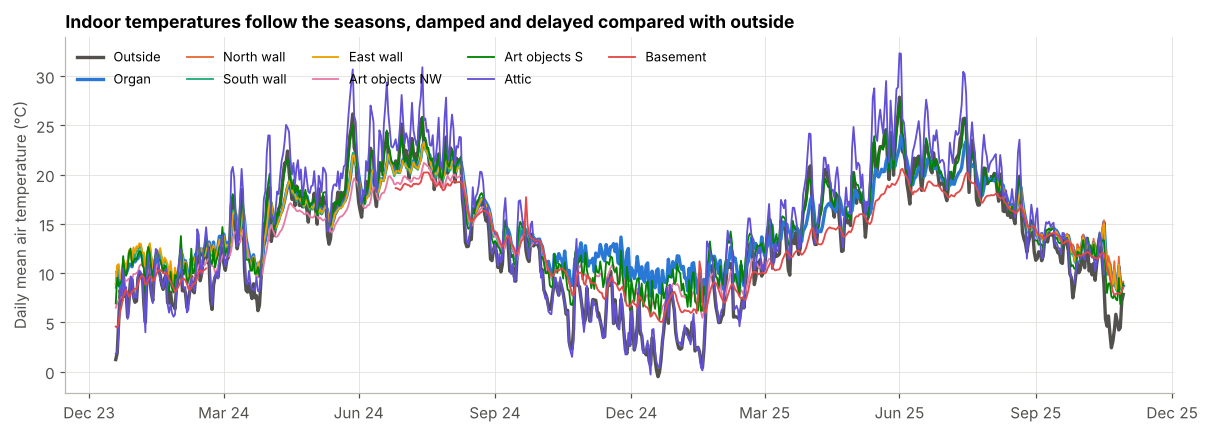

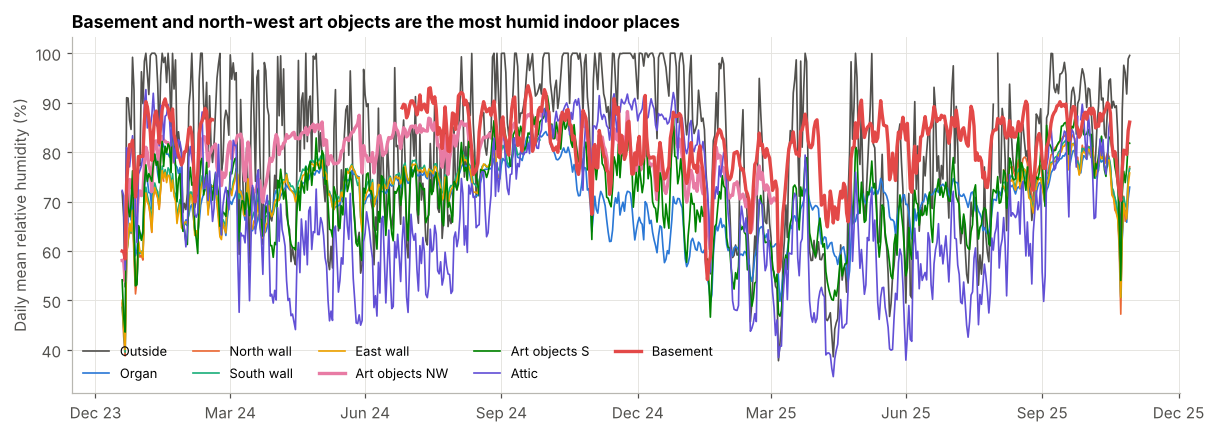

In [8]:
daily = df[temp_cols].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4.2))
for s in C.SENSORS:
    lw = 2.2 if s in ("AU", "O1") else 1.2
    ax.plot(daily.index, daily[f"temp_{s}"], label=P.name(s), color=P.LOCATION_COLORS[s], lw=lw)
ax.set_ylabel("Daily mean air temperature (°C)")
ax.set_title("Indoor temperatures follow the seasons, damped and delayed compared with outside")
ax.legend(ncol=5, fontsize=8.5, loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
P.save(fig, "02_daily_temp.png"); plt.show()

rh_cols = [f"rh_{s}" for s in C.SENSORS]
daily_rh = df[rh_cols].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4.2))
for s in C.SENSORS:
    ax.plot(daily_rh.index, daily_rh[f"rh_{s}"], label=P.name(s), color=P.LOCATION_COLORS[s],
            lw=2.2 if s in ("Ke1", "K1") else 1.1)
ax.set_ylabel("Daily mean relative humidity (%)")
ax.set_title("Basement and north-west art objects are the most humid indoor places")
ax.legend(ncol=5, fontsize=8.5, loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
P.save(fig, "02_daily_rh.png"); plt.show()

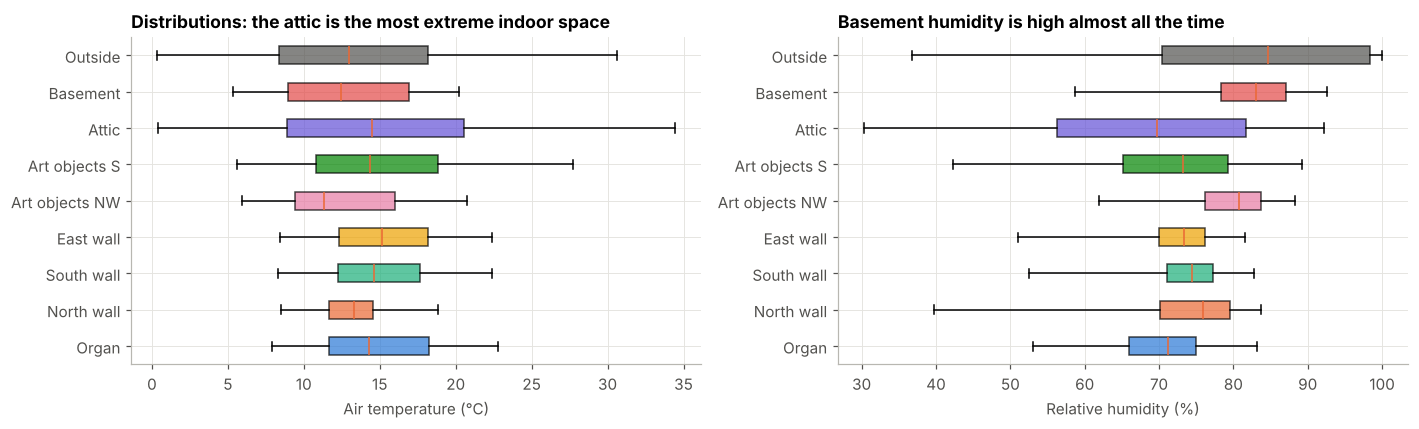

,temp_0.05,temp_0.5,temp_0.95,rh_0.05,rh_0.5,rh_0.95
O1,8.8,14.3,21.4,59.1,71.2,80.2
AWn,9.0,13.3,18.2,54.4,75.9,83.0
AWs,9.5,14.6,21.2,63.6,74.4,81.3
AWo,9.7,15.2,21.3,62.7,73.4,79.7
K1,7.2,11.3,19.7,70.0,80.8,86.8
K2,7.1,14.4,23.9,51.2,73.2,86.1
D1,2.8,14.5,29.0,37.8,69.7,89.7
Ke1,6.3,12.5,19.3,69.8,83.0,90.4
AU,2.8,13.0,24.6,47.8,84.6,100.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = C.INDOOR + ["AU"]
for ax, m, lab in [(axes[0], "temp", "Air temperature (°C)"), (axes[1], "rh", "Relative humidity (%)")]:
    data = [df[f"{m}_{s}"].dropna() for s in order]
    bp = ax.boxplot(data, orientation="horizontal", whis=(1, 99), showfliers=False, patch_artist=True)
    for patch, s in zip(bp["boxes"], order):
        patch.set_facecolor(P.LOCATION_COLORS[s]); patch.set_alpha(0.7)
    ax.set_yticks(range(1, len(order) + 1), [P.name(s) for s in order])
    ax.set_xlabel(lab)
axes[0].set_title("Distributions: the attic is the most extreme indoor space")
axes[1].set_title("Basement humidity is high almost all the time")
plt.tight_layout(); P.save(fig, "02_distributions.png"); plt.show()
dist = pd.DataFrame({f"{m}_{q}": df[[f"{m}_{s}" for s in order]].quantile(q).values
                     for m in ["temp", "rh"] for q in [0.05, 0.5, 0.95]}, index=order).round(1)
display(dist)

### Seasonal (month) and daily (hour) pattern

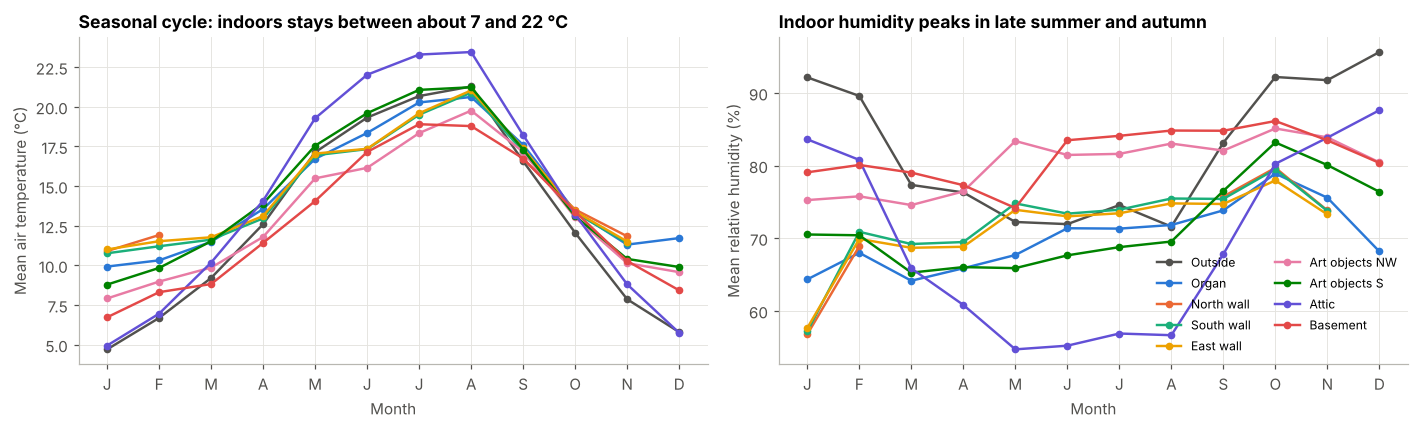

In [10]:
monthly = df[temp_cols + rh_cols].groupby(df.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for s in C.SENSORS:
    axes[0].plot(monthly.index, monthly[f"temp_{s}"], marker="o", ms=4, label=P.name(s), color=P.LOCATION_COLORS[s])
    axes[1].plot(monthly.index, monthly[f"rh_{s}"], marker="o", ms=4, label=P.name(s), color=P.LOCATION_COLORS[s])
axes[0].set_ylabel("Mean air temperature (°C)"); axes[1].set_ylabel("Mean relative humidity (%)")
for ax in axes:
    ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]); ax.set_xlabel("Month")
axes[0].set_title("Seasonal cycle: indoors stays between about 7 and 22 °C")
axes[1].set_title("Indoor humidity peaks in late summer and autumn")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); P.save(fig, "02_monthly.png"); plt.show()

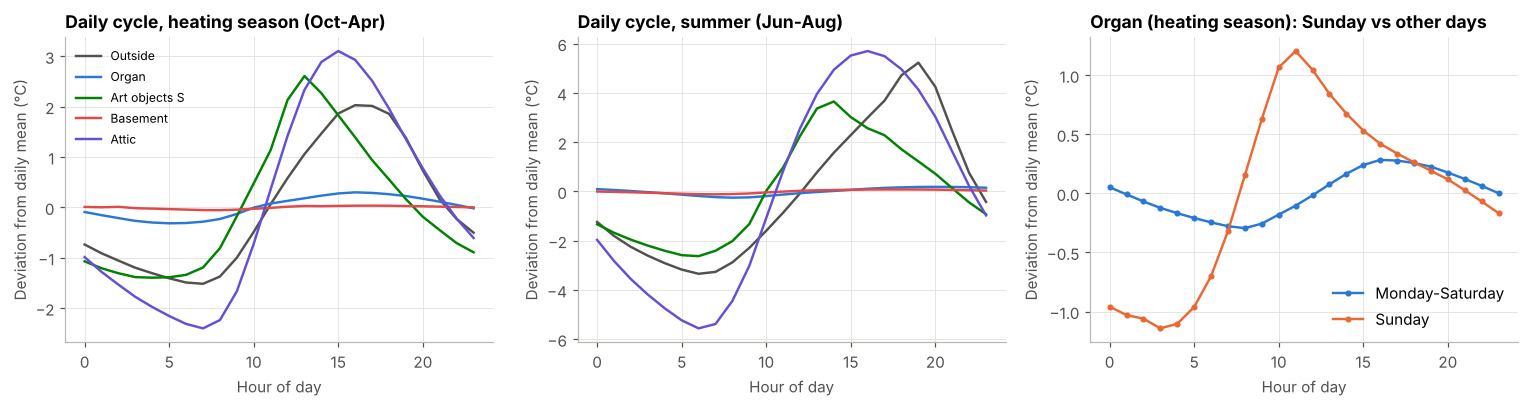

Amplitude of the mean daily cycle (°C):


,Outside,Organ,North wall,South wall,East wall,Art objects NW,Art objects S,Attic,Basement
heating season,3.54,0.61,1.05,0.50,0.74,0.21,4.00,5.50,0.09
summer,8.57,0.44,NaN,0.39,0.33,0.11,6.28,11.26,0.20


Organ temperature by weekday (heating season):


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
mean,11.79,11.38,12.10,11.70,11.46,11.46,12.53
std,2.01,2.11,1.95,1.75,1.86,1.99,1.85


In [11]:
heat = df[df.index.month.isin(C.HEATING_MONTHS)]
summer = df[df.index.month.isin([6, 7, 8])]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, (lab, d) in zip(axes[:2], [("heating season (Oct-Apr)", heat), ("summer (Jun-Aug)", summer)]):
    for s in ["AU", "O1", "K2", "Ke1", "D1"]:
        h = d[f"temp_{s}"].groupby(d.index.hour).mean()
        ax.plot(h.index, h - h.mean(), label=P.name(s), color=P.LOCATION_COLORS[s])
    ax.set_title(f"Daily cycle, {lab}"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Deviation from daily mean (°C)")
axes[0].legend(fontsize=8)
# weekday vs Sunday at the organ, heating season
org = heat["temp_O1"]
dev = org - org.groupby(org.index.date).transform("mean")
for lab, mask, col in [("Monday-Saturday", heat.index.weekday < 6, P.SERIES[0]), ("Sunday", heat.index.weekday == 6, P.SERIES[1])]:
    h = dev[mask].groupby(dev[mask].index.hour).mean()
    axes[2].plot(h.index, h, label=lab, color=col, marker="o", ms=3)
axes[2].set_title("Organ (heating season): Sunday vs other days"); axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel("Deviation from daily mean (°C)"); axes[2].legend()
plt.tight_layout(); P.save(fig, "02_daily_cycle.png"); plt.show()

amp = pd.DataFrame({P.name(s): [d[f"temp_{s}"].groupby(d.index.hour).mean().pipe(lambda h: h.max() - h.min())
                                for d in (heat, summer)] for s in C.SENSORS},
                   index=["heating season", "summer"]).round(2)
print("Amplitude of the mean daily cycle (°C):"); display(amp)
wk = heat.groupby(heat.index.weekday)["temp_O1"].agg(["mean", "std"]).round(2)
wk.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Organ temperature by weekday (heating season):"); display(wk.T)

### Indoor vs outdoor

In [12]:
io = pd.DataFrame({
    "mean temp inside - outside (°C)": [(df[f"temp_{s}"] - df["temp_AU"]).mean() for s in C.INDOOR],
    "winter (DJF)": [(df[f"temp_{s}"] - df["temp_AU"])[df.index.month.isin([12, 1, 2])].mean() for s in C.INDOOR],
    "summer (JJA)": [(df[f"temp_{s}"] - df["temp_AU"])[df.index.month.isin([6, 7, 8])].mean() for s in C.INDOOR],
    "mean abs. humidity inside - outside (g/m³)": [(df[f"abs_hum_{s}"] - df["abs_hum_AU"]).mean() for s in C.INDOOR],
    "share of time outside air is drier (abs.)": [(df[f"abs_hum_{s}"] > df["abs_hum_AU"])[df[f"abs_hum_{s}"].notna()].mean() for s in C.INDOOR],
}, index=[P.name(s) for s in C.INDOOR]).round(2)
display(io)
results.save_table(io, "indoor_outdoor")

,mean temp inside - outside (°C),winter (DJF),summer (JJA),mean abs. humidity inside - outside (g/m³),share of time outside air is drier (abs.)
Organ,1.49,4.67,-0.66,-0.43,0.42
North wall,2.39,3.43,NaN,-0.22,0.42
South wall,0.88,2.91,-0.89,-0.61,0.35
East wall,0.99,3.21,-0.82,-0.60,0.36
Art objects NW,0.63,3.01,-2.07,-0.16,0.50
Art objects S,1.52,3.68,0.23,-0.34,0.42
Attic,1.38,0.18,2.53,-1.03,0.09
Basement,0.02,1.99,-2.61,0.14,0.57


**Decisions (patterns):**
* The church is a slow, heavy building: indoor daily cycles are small (organ well below
  1 °C on average) while outside swings by several degrees. **Short-term outside weather
  matters little; season matters a lot** → mold risk features use rolling windows of
  days to weeks and the month / heating-season flags.
* Indoor air is warmer than outside in winter and cooler in summer; absolute humidity
  indoors is close to outside on average → **no strong internal moisture source**; the
  humidity mainly comes in from outside. In summer, warm humid outside air entering the
  cool church (and the even cooler basement) raises the relative humidity → summer
  ventilation can *increase* risk. This motivates the ventilation rule "only ventilate
  when the outside absolute humidity is lower than inside".
* On Sundays the organ shows a morning warm-up (services), but rapid changes are not
  limited to Sundays (see notebook 05).

## 4 · Cross-sensor correlation and lagged response to outside temperature

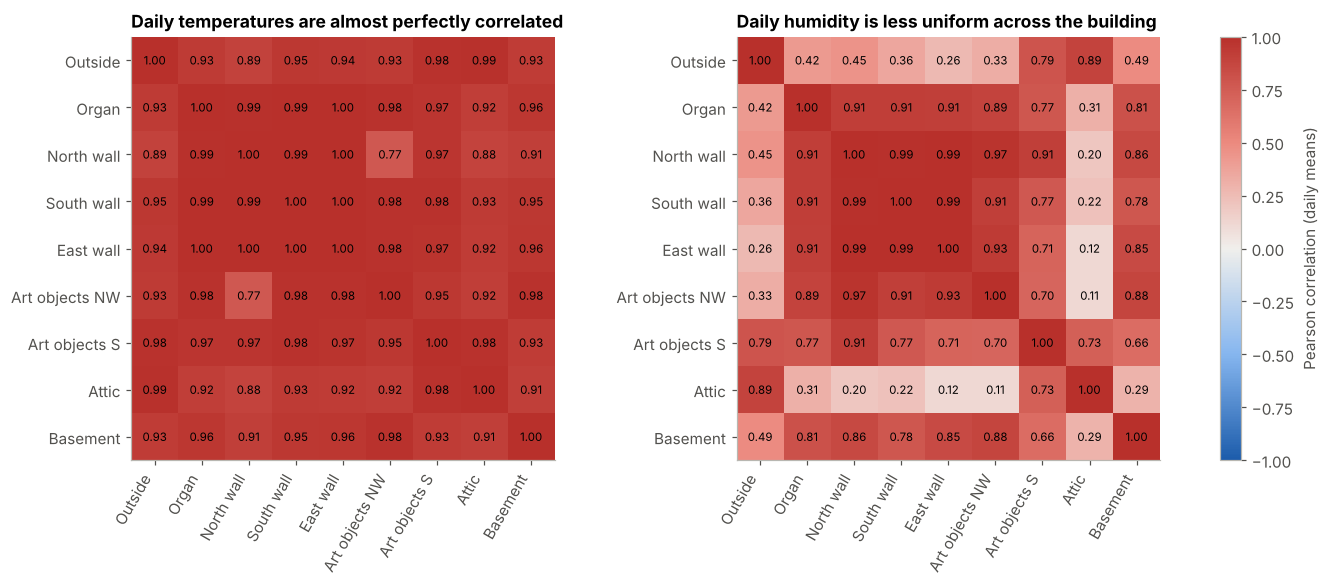

In [13]:
dm = df[temp_cols + rh_cols].resample("D").mean()
corr = dm[temp_cols].corr()
corr.index = corr.columns = [P.name(s) for s in C.SENSORS]
corr_rh = dm[rh_cols].corr()
corr_rh.index = corr_rh.columns = [P.name(s) for s in C.SENSORS]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cm, t in [(axes[0], corr, "Daily temperatures are almost perfectly correlated"),
                  (axes[1], corr_rh, "Daily humidity is less uniform across the building")]:
    im = ax.imshow(cm, cmap=P.DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cm)), cm.columns, rotation=60, ha="right"); ax.set_yticks(range(len(cm)), cm.index)
    for i in range(len(cm)):
        for j in range(len(cm)):
            if not np.isnan(cm.iloc[i, j]):
                ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
    ax.grid(False); ax.set_title(t)
fig.colorbar(im, ax=axes, fraction=0.02, label="Pearson correlation (daily means)")
P.save(fig, "02_correlation.png"); plt.show()

The seasonal cycle dominates any correlation of raw temperatures (everything is warm in
summer), and the daily cycle creates artificial peaks at multiples of 24 h. To measure how
fast the building *reacts to weather*, we (1) take hourly means (outside readings flagged
as direct sun excluded), (2) smooth them with a centred 24-hour mean to remove the daily
cycle, (3) subtract a centred 7-day mean to remove the season. The remaining "weather
anomaly" of the outside temperature at time *t* is correlated with each indoor anomaly
at *t + lag* for lags 0–48 h.

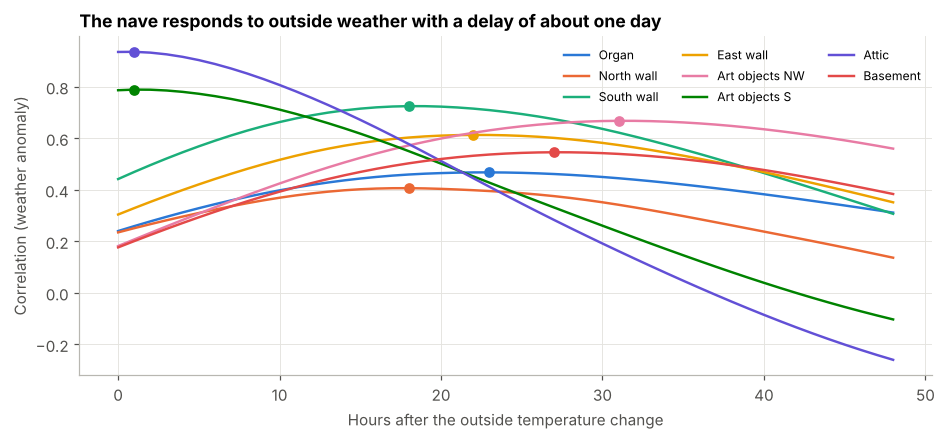

,lag of max correlation (h),max correlation,correlation at lag 0
Organ,23,0.47,0.24
North wall,18,0.41,0.24
South wall,18,0.73,0.44
East wall,22,0.61,0.30
Art objects NW,31,0.67,0.18
Art objects S,1,0.79,0.79
Attic,1,0.94,0.94
Basement,27,0.55,0.18


In [14]:
hourly = df[temp_cols].copy()
hourly.loc[df["flag_sun_AU"], "temp_AU"] = np.nan
hourly = hourly.resample("h").mean()
smooth = hourly.rolling(24, center=True, min_periods=18).mean()                  # remove daily cycle
anom = smooth - hourly.rolling(24 * 7, center=True, min_periods=24 * 4).mean()   # remove season
lags = range(0, 49)
lag_corr = pd.DataFrame({s: [anom["temp_AU"].corr(anom[f"temp_{s}"].shift(-k)) for k in lags] for s in C.INDOOR}, index=lags)
fig, ax = plt.subplots(figsize=(10, 4))
for s in C.INDOOR:
    ax.plot(lag_corr.index, lag_corr[s], label=P.name(s), color=P.LOCATION_COLORS[s])
    k = lag_corr[s].idxmax(); ax.plot(k, lag_corr[s].max(), "o", color=P.LOCATION_COLORS[s])
ax.set_xlabel("Hours after the outside temperature change"); ax.set_ylabel("Correlation (weather anomaly)")
ax.set_title("The nave responds to outside weather with a delay of about one day")
ax.legend(ncol=3, fontsize=8)
P.save(fig, "02_lag_correlation.png"); plt.show()
best = pd.DataFrame({"lag of max correlation (h)": lag_corr.idxmax(), "max correlation": lag_corr.max().round(2),
                     "correlation at lag 0": lag_corr.iloc[0].round(2)})
best.index = [P.name(s) for s in best.index]
display(best)
results.save_table(best, "lag_correlation")
results.update(lag_organ_h=int(lag_corr["O1"].idxmax()), lag_basement_h=int(lag_corr["Ke1"].idxmax()),
               lag_attic_h=int(lag_corr["D1"].idxmax()))

**Decision (correlation and lag):** daily indoor temperatures are almost collinear,
so they carry little independent information → features use *differences*
(inside − outside, surface − air, inside − outside absolute humidity) rather than raw
levels. The attic follows the weather almost immediately (lag ≈ 1 h, correlation 0.94).
The nave (organ, walls) and the basement respond with a delay of **about one day
(18–27 h)**, the north-west art objects (thick corner masonry) after about 31 h. The
upper south art-object sensor reacts within an hour (correlation 0.79) and has a 4–6 °C
daily cycle: it sits near the south window and is exposed to sun, so its air temperature
is not representative of the nave; we report this as a limitation and as a conservation
issue (sun on art objects). For early warning this means a 24-hour horizon is
meaningful: today's weather is tomorrow's indoor climate. The model in notebook 04
therefore uses 24-hour means and changes of outside conditions.